# IRWA - Part 1: Text Processing and Exploratory Data Analysis

In [25]:
#We import the libraries and load the NLTK resources (English stop words and the Porter stemmer)

import json
import re
import csv
import collections
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords", quiet=True)
STOPWORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()

# DATA_PATH = "/Users/mrv/Desktop/data/fashion_products_dataset.json"
# LABELS_PATH = "/Users/mrv/Desktop/data/validation_labels.csv"
FIG_DIR = "figures"
DATA_PATH = "../../data/fashion_products_dataset.json"
LABELS_PATH = "../../data/validation_labels.csv"


In [26]:
#Loading the data - The dataset is a list of products in JSON format, where each product has the fields shown in the appendix

with open(DATA_PATH, encoding="utf-8") as f:
    raw_docs = json.load(f)

print("Number of products:", len(raw_docs))

example = raw_docs[0]
for key, value in example.items():
    if key == "images":
        continue  #images not needed
    print(f"{key:16s}: {str(value)[:90]}")

Number of products: 28080
_id             : fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a
actual_price    : 2,999
average_rating  : 3.9
brand           : York
category        : Clothing and Accessories
crawled_at      : 1612987911000
description     : Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Com
discount        : 69% off
out_of_stock    : False
pid             : TKPFCZ9EA7H5FYZH
product_details : [{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabr
seller          : Shyam Enterprises
selling_price   : 921
sub_category    : Bottomwear
title           : Solid Women Multicolor Track Pants
url             : https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76aadce459?pid=TK


## Part 1 - Data preparation

### 1.1 Pre-processing

In [27]:
#Text pre-processing pipeline

#Lowercase and split into alphanumeric tokens (removes punctuation)
def tokenize(text):
    if not text: return []
    return re.findall(r"[a-z0-9]+", str(text).lower())

#Remove NLTK stop words
def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS]

#Apply the Porter stemmer to each token
def stem_tokens(tokens):
    return [STEMMER.stem(t) for t in tokens]



# full preprocessing
def preprocess_text(text):
    return stem_tokens(remove_stopwords(tokenize(text)))

In [28]:
#We test the pipeline step by step on a real-looking product string to see what each function does

sample = "Women's Full-Sleeve Printed Sweatshirts (Pack of 2) - 100% cotton!"

print("1. tokenize:          ", tokenize(sample))
print("2. remove_stopwords:  ", remove_stopwords(tokenize(sample)))
print("3. preprocess_text:   ", preprocess_text(sample))

print("\n'shirt' and 'shirts' after stemming:", preprocess_text("shirt"), preprocess_text("shirts"))

1. tokenize:           ['women', 's', 'full', 'sleeve', 'printed', 'sweatshirts', 'pack', 'of', '2', '100', 'cotton']
2. remove_stopwords:   ['women', 'full', 'sleeve', 'printed', 'sweatshirts', 'pack', '2', '100', 'cotton']
3. preprocess_text:    ['women', 'full', 'sleev', 'print', 'sweatshirt', 'pack', '2', '100', 'cotton']

'shirt' and 'shirts' after stemming: ['shirt'] ['shirt']


In [29]:
#Domain stop words:  NLTK's list doesnt contain domain specific stopwords, and we dont want to add any

DOMAIN_STOPWORDS = set()  # empty 

#Remove NLTK stop words and domain stop words (if any)
def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS and t not in DOMAIN_STOPWORDS]

print("Example with 'men slim jeans blue':", preprocess_text("men slim jeans blue"))

Example with 'men slim jeans blue': ['men', 'slim', 'jean', 'blue']


### 1.2 Output files

In [30]:
#The results returned to the user must contain these fields when they are present
#We define the list once, so that every later step (indexing, ranking, the web interface) returns the same information. 
#pid is kept because the evaluation uses it.

OUTPUT_FIELDS = [
    "pid", "title", "description", "brand", "category", "sub_category",
    "product_details", "seller", "out_of_stock", "selling_price", "discount",
    "actual_price", "average_rating", "url",
]

print("Fields returned for each document:", len(OUTPUT_FIELDS))

Fields returned for each document: 14


### 1.3 Categorical fields - brand, category, sub_category, seller

In [31]:
#We store each one as a single normalised label, in lowercase. 
#DECISION - each categorical field is an exact label and is not stemmed

# Lowercase and collapse whitespace. Returns None if the value is empty.
def normalise_label(value):
    if value is None: return None
    label = re.sub(r"\s+", " ", str(value)).strip().lower()
    return label or None


print(normalise_label("Clothing and Accessories"))
print(normalise_label("  Bottomwear  "))
print(normalise_label(""))

clothing and accessories
bottomwear
None


In [32]:
#product_details field
#We convert product_details to text keeping the keys and the result is then processed as free text.

# for ex: Turn [{"Color": "Blue"}, {"Fabric": "Cotton"}] into "Color Blue Fabric Cotton".
def product_details_to_text(details):
    if not details: return ""
    parts = []
    for item in details:
        if isinstance(item, dict):
            for key, value in item.items():
                parts.append(f"{key} {value}")
        else:
            parts.append(str(item))
    return " ".join(parts)


example_details = raw_docs[0]["product_details"]
print(product_details_to_text(example_details))
print(preprocess_text(product_details_to_text(example_details)))

Style Code 1005COMBO2 Closure Elastic Pockets Side Pockets Fabric Cotton Blend Pattern Solid Color Multicolor
['style', 'code', '1005combo2', 'closur', 'elast', 'pocket', 'side', 'pocket', 'fabric', 'cotton', 'blend', 'pattern', 'solid', 'color', 'multicolor']


### 1.4 Numeric fields - selling_price, actual_price, discount, average_rating, out_of_stock

In [33]:
#We convert them to numbers before using them
#DECISION - we do not index them as text terms (we keep them as numeric metadata) as a number used as a token means nothing to a user searching by words, and it would mix non-text data into the text index 

# for ex: "2,999" -> 2999.0 ; "" or None -> None
def parse_price(value):
    if value is None: return None
    try:
        return float(str(value).replace(",", "").strip())
    except ValueError:
        return None

# for ex: "69% off" -> 69.0 ; "" -> None
def parse_discount(value):
    if not value: return None
    match = re.search(r"(\d+(?:\.\d+)?)\s*%", str(value))
    return float(match.group(1)) if match else None


# for ex: "3.9" -> 3.9 ; "" -> None
def parse_rating(value):
    if value is None or str(value).strip() == "": return None
    try:
        return float(value)
    except ValueError:
        return None


# accepts numbers or strings
def parse_bool(value):
    if isinstance(value, bool): return value
    if value is None: return None
    text = str(value).strip().lower()
    if text in {"true", "1", "yes"}:
        return True
    if text in {"false", "0", "no"}:
        return False
    return None


print(parse_price("2,999"), parse_discount("69% off"), parse_rating("3.9"), parse_bool("false"))
print(parse_price(""), parse_discount(""), parse_rating(""))

2999.0 69.0 3.9 False
None None None


### Applying the pipeline to the whole corpus

In [34]:
#Transform one JSON product into the structure used by the index.
def process_document(raw):
    details = raw.get("product_details") or []
    fields = {
        "title": preprocess_text(raw.get("title")),
        "description": preprocess_text(raw.get("description")),
        "product_details": preprocess_text(product_details_to_text(details)),
    }
    labels = {
        "brand": normalise_label(raw.get("brand")),
        "category": normalise_label(raw.get("category")),
        "sub_category": normalise_label(raw.get("sub_category")),
        "seller": normalise_label(raw.get("seller")),
    }
    numeric = {
        "selling_price": parse_price(raw.get("selling_price")),
        "actual_price": parse_price(raw.get("actual_price")),
        "discount": parse_discount(raw.get("discount")),
        "average_rating": parse_rating(raw.get("average_rating")),
        "out_of_stock": parse_bool(raw.get("out_of_stock")),
    }
    display = {field: raw.get(field) for field in OUTPUT_FIELDS}
    display["product_details"] = details
    return {"pid": raw.get("pid"), "fields": fields, "labels": labels,
            "numeric": numeric, "display": display}


processed = [process_document(d) for d in raw_docs]

pids = [d["pid"] for d in processed]
print("Processed documents:", len(processed))
print("Unique pids:", len(set(pids)), "(must match)")
print("All output fields present in the first document:", all(f in processed[0]["display"] for f in OUTPUT_FIELDS))

Processed documents: 28080
Unique pids: 28080 (must match)
All output fields present in the first document: True


## Part 2 – Exploratory Data Analysis

### Empty values per field

In [35]:
df = pd.DataFrame(raw_docs)
missing = {}
for col in df.columns:
    if col == "images": continue
    empty = df[col].isna() | (df[col].astype(str).str.strip() == "")
    missing[col] = int(empty.sum())

missing_df = pd.DataFrame.from_dict(missing, orient="index", columns=["empty"])
missing_df["percentage"] = (missing_df["empty"] / len(df) * 100).round(1)
missing_df.sort_values("empty", ascending=False)

,empty,percentage
description,11150,39.7
average_rating,2261,8.1
brand,2009,7.2
seller,1643,5.9
discount,855,3.0
actual_price,777,2.8
selling_price,2,0.0
_id,0,0.0
category,0,0.0
crawled_at,0,0.0


### Length of titles and descriptions

Titles (tokens):
count    28080.00
mean         6.93
std          2.35
min          1.00
25%          6.00
50%          7.00
75%          8.00
max         36.00
Name: title, dtype: float64

Descriptions (tokens):
count    28080.00
mean        30.71
std         45.84
min          0.00
25%          0.00
50%         11.00
75%         50.00
max        693.00
Name: description, dtype: float64


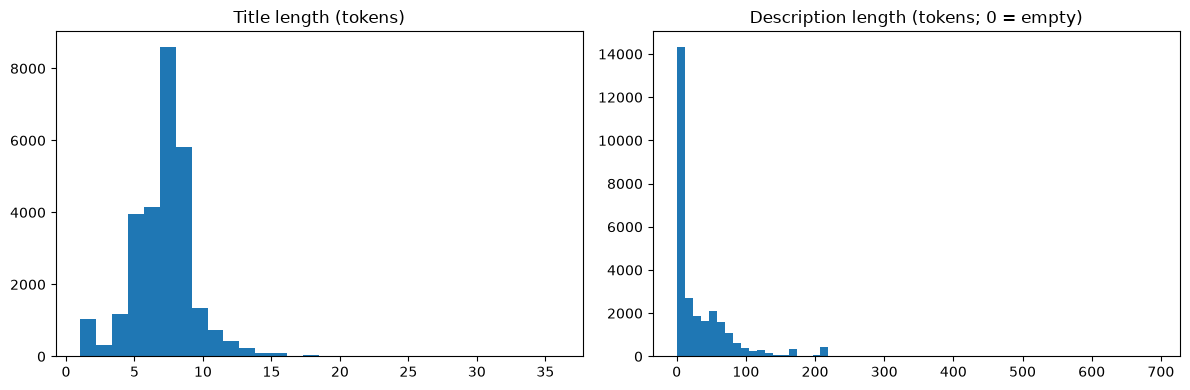

In [36]:
title_len = df["title"].fillna("").map(lambda t: len(tokenize(t)))
desc_len = df["description"].fillna("").map(lambda t: len(tokenize(t)))

print("Titles (tokens):")
print(title_len.describe().round(2))
print()
print("Descriptions (tokens):")
print(desc_len.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(title_len, bins=30)
axes[0].set_title("Title length (tokens)")
axes[1].hist(desc_len, bins=60)
axes[1].set_title("Description length (tokens; 0 = empty)")
plt.tight_layout()
plt.show()

### Sentences and average sentence length

In [37]:
#we use NLTK's sent_tokenize

nltk.download("punkt_tab", quiet=True)
from nltk.tokenize import sent_tokenize

# Split a text into sentences with NLTK's Punkt tokenizer
def split_sentences(text):
    if not text: return []
    return [s for s in sent_tokenize(str(text)) if s.strip()]


sentences_per_doc = df["description"].fillna("").map(lambda t: len(split_sentences(t)))
sentence_lengths = [len(tokenize(s)) for text in df["description"].fillna("") for s in split_sentences(text)]

print("Sentences per description:")
print(sentences_per_doc.describe().round(2))
print("\nAverage sentence length (tokens):", round(np.mean(sentence_lengths), 2))

Sentences per description:
count    28080.00
mean         1.89
std          2.81
min          0.00
25%          0.00
50%          1.00
75%          3.00
max         31.00
Name: description, dtype: float64

Average sentence length (tokens): 16.23


### Vocabulary size

In [38]:
#We compare the vocabulary before and after pre-processing, using the same fields so the comparison is fair

raw_vocab = Counter()
for text in pd.concat([df["title"].fillna(""), df["description"].fillna("")]):
    raw_vocab.update(tokenize(text))

proc_vocab = Counter()
for doc in processed:
    proc_vocab.update(doc["fields"]["title"])
    proc_vocab.update(doc["fields"]["description"])

print("Raw vocabulary (unique tokens):", len(raw_vocab))
print("Processed vocabulary (stop words removed + stemming):", len(proc_vocab))

Raw vocabulary (unique tokens): 6503
Processed vocabulary (stop words removed + stemming): 4902


### Most frequent terms

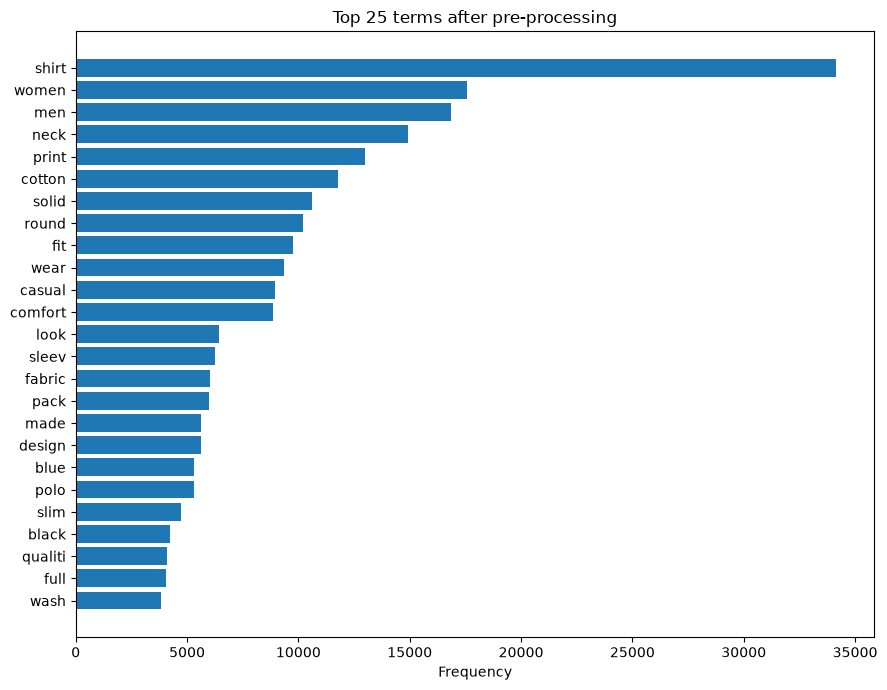

Frequency of 'men': 16835
Frequency of 'women': 17570


In [39]:
#Chart of the most frequent terms after pre-processing.

top_terms = proc_vocab.most_common(25)
terms, counts = zip(*top_terms)

plt.figure(figsize=(9, 7))
plt.barh(list(terms)[::-1], list(counts)[::-1])
plt.title("Top 25 terms after pre-processing")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()

print("Frequency of 'men':", proc_vocab["men"])
print("Frequency of 'women':", proc_vocab["women"])

### Word cloud

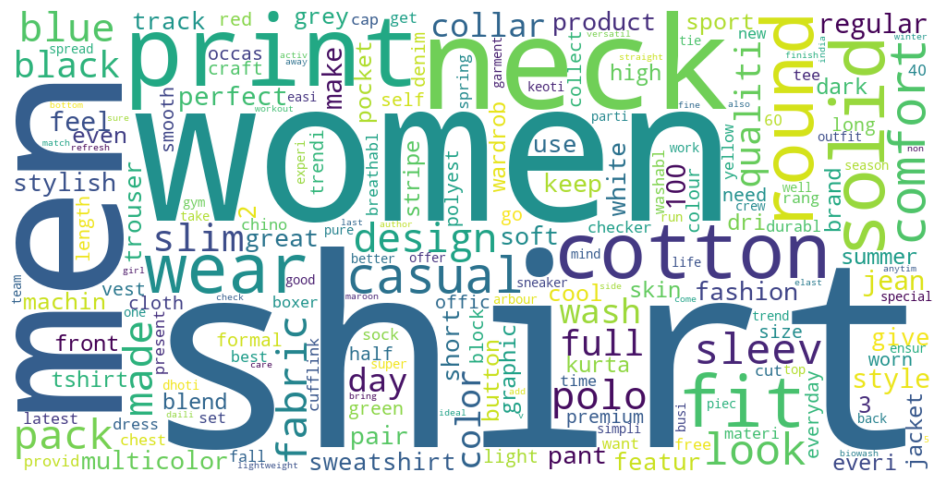

In [40]:
from wordcloud import WordCloud
wc = WordCloud(width=1000, height=500, background_color="white")
wc.generate_from_frequencies(dict(proc_vocab))
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()


### Distribution of categories, subcategories and brands

Categories:
category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64

Subcategories (top 10):
sub_category
Topwear                            15310
Bottomwear                          3666
Winter Wear                         2493
Innerwear and Swimwear              1762
Clothing Accessories                1742
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Name: count, dtype: int64


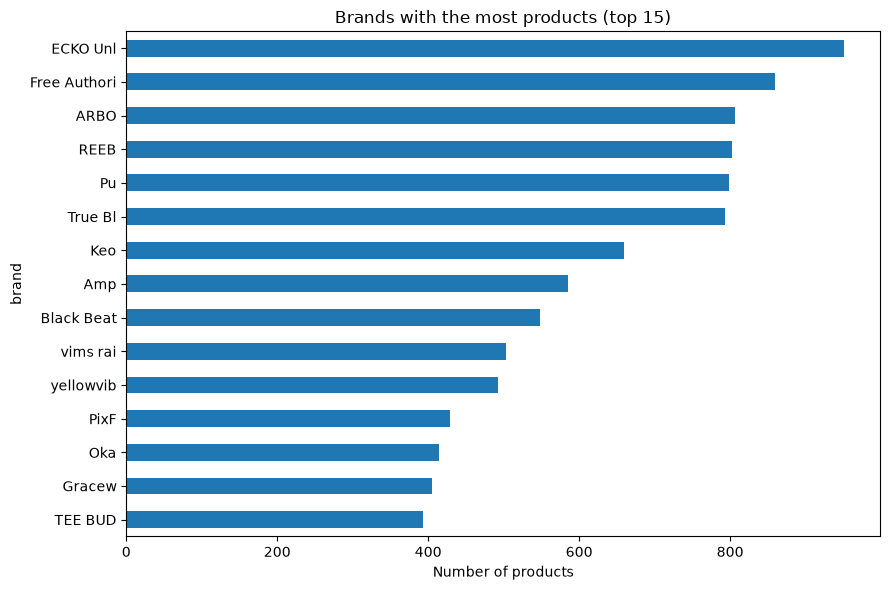

In [41]:
print("Categories:")
print(df["category"].value_counts())
print("\nSubcategories (top 10):")
print(df["sub_category"].value_counts().head(10))

brands = df["brand"].replace("", np.nan).dropna()
top_brands = brands.value_counts().head(15)

plt.figure(figsize=(9, 6))
top_brands.sort_values().plot.barh()
plt.title("Brands with the most products (top 15)")
plt.xlabel("Number of products")
plt.tight_layout()
plt.show()

### Rating, price, discount and stock

       selling_price  actual_price  discount  average_rating
count       28078.00      27303.00  27225.00        25819.00
mean          705.64       1455.53     50.26            3.63
std           549.68        939.98     16.89            0.66
min            99.00        150.00      1.00            1.00
25%           390.00        849.00     40.00            3.20
50%           545.00       1199.00     53.00            3.80
75%           820.00       1799.00     63.00            4.10
max          7999.00      12999.00     87.00            5.00


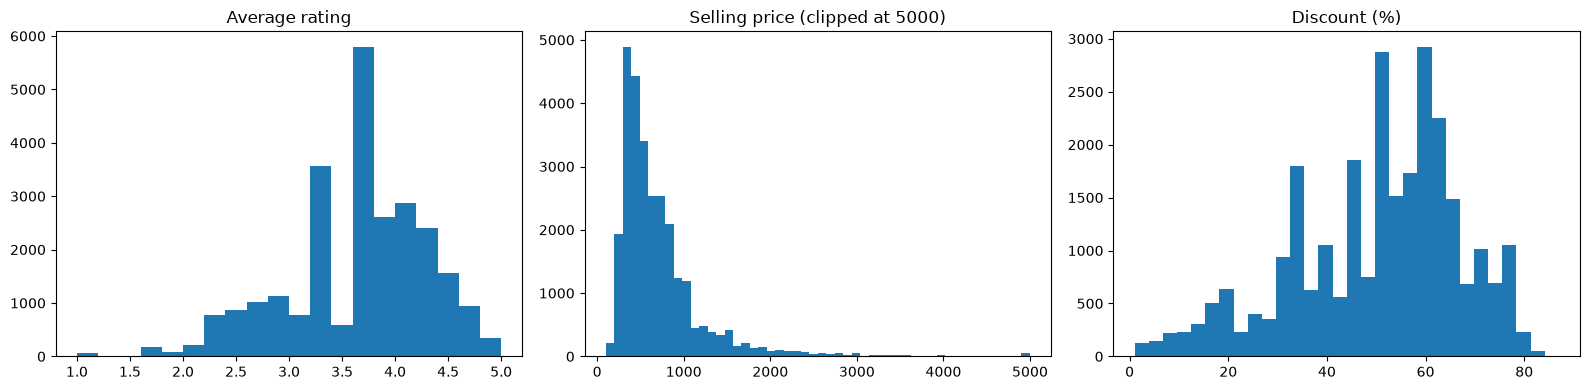

In [42]:
#We use the parsed numeric values
#Products without a rating or price are left out

num = pd.DataFrame([d["numeric"] for d in processed])
print(num.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(num["average_rating"].dropna(), bins=20)
axes[0].set_title("Average rating")
axes[1].hist(num["selling_price"].dropna().clip(upper=5000), bins=50)
axes[1].set_title("Selling price (clipped at 5000)")
axes[2].hist(num["discount"].dropna(), bins=30)
axes[2].set_title("Discount (%)")
plt.tight_layout()
plt.show()

In [43]:
oos_share = num["out_of_stock"].mean()
print(f"Out of stock: {oos_share:.2%}")

oos_by_sub = (df.assign(oos=num["out_of_stock"].astype(float))
                .groupby("sub_category")["oos"].agg(["mean", "size"])
                .query("size >= 50")
                .sort_values("mean", ascending=False)
                .head(10))
oos_by_sub

Out of stock: 5.85%


,mean,size
sub_category,,
Clothing Accessories,0.168772,1742
Tracksuits,0.144444,90
Winter Wear,0.095066,2493
Sleepwear,0.090164,122
Bottomwear,0.074741,3666
"Blazers, Waistcoats and Suits",0.058252,103
Innerwear and Swimwear,0.053348,1762
Topwear,0.044350,15310
"Kurtas, Ethnic Sets and Bottoms",0.019492,1180


### Rankings: brands and products

In [44]:
#we use the brands with the most well-rated products (rating more or equal to 4)

ranking = pd.DataFrame({"brand": df["brand"], "rating": num["average_rating"]})
good = (ranking[ranking["rating"] >= 4]
        .assign(brand=lambda x: x["brand"].replace("", np.nan))
        .dropna(subset=["brand"])
        .groupby("brand").size()
        .sort_values(ascending=False)
        .head(10))
good

brand
ARBO             623
Pu               567
REEB             493
Marca Disa       323
Gracew           318
PixF             309
Cots             234
Black Beat       220
TOM BU           207
M7 By Metrona    180
dtype: int64

### Named entities

In [45]:
import spacy
nlp = spacy.load("en_core_web_sm")
sample_text = " ".join(df["description"].fillna("").head(200))
entities = Counter(ent.label_ for ent in nlp(sample_text).ents)
print(entities.most_common(10))

[('ORG', 179), ('DATE', 169), ('PERSON', 86), ('WORK_OF_ART', 39), ('ORDINAL', 39), ('PERCENT', 25), ('GPE', 6), ('NORP', 6), ('FAC', 4), ('TIME', 4)]


### Analysis of the validation labels

In [46]:
#we check which product characteristics separate relevant from non-relevant items

with open(LABELS_PATH, encoding="utf-8") as f:
    labels_rows = list(csv.DictReader(f))

print("Rows:", len(labels_rows))
print(Counter((r["query_id"], r["labels"]) for r in labels_rows))

by_pid = {d["pid"]: d for d in processed}
for q in ["1", "2"]:
    for lab in ["1", "0"]:
        rows = [r for r in labels_rows if r["query_id"] == q and r["labels"] == lab]
        cotton = sum("cotton" in preprocess_text(
            (by_pid[r["pid"]]["display"]["description"] or "") + " " +
            product_details_to_text(by_pid[r["pid"]]["display"]["product_details"])) for r in rows)
        women = sum("women" in preprocess_text(by_pid[r["pid"]]["display"]["title"]) for r in rows)
        print(f"query {q}, label {lab}: n={len(rows)}, with 'cotton': {cotton}, with 'women' in title: {women}")

Rows: 40
Counter({('1', '1'): 13, ('2', '1'): 10, ('2', '0'): 10, ('1', '0'): 7})
query 1, label 1: n=13, with 'cotton': 13, with 'women' in title: 13
query 1, label 0: n=7, with 'cotton': 7, with 'women' in title: 7
query 2, label 1: n=10, with 'cotton': 8, with 'women' in title: 3
query 2, label 0: n=10, with 'cotton': 6, with 'women' in title: 8
